# Phase 3: Implementation and execution
AI2002 Artificial Intelligence, Fall 2026 · Track B · Group 6

Ahmad Ali Khan (Lead, 24L-3049) · Talha Pasha (24L-3005) · Moeed Amir (24L-3060) · Bilal Kashif (24L-3036)

Run from the repository root. The notebook reads the saved outputs in `results/`; it loads no model and needs no GPU.

In [1]:
import json, platform, runpy
from collections import Counter
from datetime import datetime
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
from src.common.io import ROOT, load_config
from src.common.text import matches, stem_match
from scripts import handcheck

RESULTS = ROOT / 'results'
LANGS = [p.parent for p in sorted(RESULTS.glob('*/*/answers.jsonl'))]

def read_jsonl(path):
    return [json.loads(l) for l in path.read_text(encoding='utf-8').splitlines() if l.strip()]

runs = {(p.parent.name, p.name): json.loads((p / 'run.json').read_text(encoding='utf-8')) for p in LANGS}
print('python', platform.python_version(), '|', platform.platform())

python 3.11.9 | Windows-10-10.0.26300-SP0


## 1. Run machine and environment
Versions are the block that `scripts/check_gpu.py` wrote on the run machine. Times come from the `run.json` of each folder.

In [2]:
text = (RESULTS / 'README.md').read_text(encoding='utf-8')
print(text[text.index('## Machine versions'):])
rows = []
for dataset in ['mtrex', 'xfactr', 'psiloqa']:
    r = [v for (d, _), v in runs.items() if d == dataset]
    start = min(datetime.fromisoformat(x['started']) for x in r)
    end = max(datetime.fromisoformat(x['ended']) for x in r)
    rows.append([dataset, r[0]['gpu'], start, end, round((end - start).total_seconds() / 3600, 2), sum(x['items'] for x in r)])
pd.DataFrame(rows, columns=['dataset', 'gpu', 'first start', 'last end', 'hours (first start to last end)', 'items'])

## Machine versions

`scripts/check_gpu.py` appends one block per machine below.

## DESKTOP-O11JBVQ
- torch: 2.15.0+cu132
- transformers: 5.22.1
- CUDA: 13.2
- driver: 596.71
- GPU: NVIDIA RTX A4000
- peak VRAM (GiB): 5.73



,dataset,gpu,first start,last end,hours (first start to last end),items
0,mtrex,NVIDIA RTX A4000,2026-11-06 00:23:11,2026-11-06 19:50:43,19.46,32100
1,xfactr,NVIDIA RTX A4000,2026-11-06 19:50:43,2026-11-06 23:35:08,3.74,9977
2,psiloqa,NVIDIA RTX A4000,2026-11-06 23:35:08,2026-11-06 23:52:43,0.29,5000


## 2. Model selection
One generator for every experiment: Llama-3.1-8B-Instruct, loaded in 4-bit NF4 with bitsandbytes so it fits a 16 GB GPU. The answer is greedy. mTREx and X-FACTR answers have at most 50 new tokens, PsiloQA answers at most the value of `psiloqa_max_new_tokens` below.

In [3]:
run = runs[('mtrex', 'en')]
q = run['quantization']
display(pd.Series({'model': run['model'], 'submodule commit': run['submodule_commit'][:7], 'seeds': run['seeds'],
                   '4-bit': q['load_in_4bit'], 'quant type': q['bnb_4bit_quant_type'],
                   'double quant': q['bnb_4bit_use_double_quant'], 'compute dtype': q['bnb_4bit_compute_dtype']}, name='value').to_frame())
print('generation_config of the model files (applies to the sampled answers):')
print({k: v for k, v in run['generation_config'].items() if k in ('do_sample', 'temperature', 'top_p', 'top_k', 'eos_token_id')})
run_cfg = yaml.safe_load((ROOT / 'configs' / 'run.yaml').read_text(encoding='utf-8'))
print('max new tokens: mtrex and xfactr 50, psiloqa', run_cfg['psiloqa_max_new_tokens'])

,value
model,meta-llama/Llama-3.1-8B-Instruct
submodule commit,644d655
seeds,"[42, 43, 44]"
4-bit,True
quant type,nf4
double quant,False
compute dtype,bfloat16


generation_config of the model files (applies to the sampled answers):
{'do_sample': True, 'temperature': 0.6, 'top_k': None, 'top_p': 0.9, 'eos_token_id': [128001, 128008, 128009]}
max new tokens: mtrex and xfactr 50, psiloqa 264


## 3. Pipeline
1. Processed data in the shared schema (Phase 2).
2. One greedy answer per item. The label is 1 (hallucinated) unless `matches()` finds a gold alias in the answer; PsiloQA uses the span label.
3. MAM: the model's first-token activations (last layer, fully connected and attention) go to a small classifier.
4. 20 samples at temperature 1 per item: SelfCheckGPT (unigram score) and Semantic Entropy.

Run sizes and the stage log:

In [4]:
print({k: v for k, v in run_cfg.items() if k != 'measured'})
log = (RESULTS / 'RUNS.md').read_text(encoding='utf-8')
display(Markdown(log[log.index('| date'):]))

{'mam_limit': None, 'sampling_limit': {'mtrex': 91, 'xfactr': 91, 'psiloqa': 91}, 'psiloqa_max_new_tokens': 264, 'num_samples': 20, 'sample_chunk': 20, 'sample_step': 50}


| date | machine | command | commit |
|---|---|---|---|
| 2026-11-06T09:23:12 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | smoke | 43f1b17 |
| 2026-11-06T09:36:09 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | verify --partial | 43f1b17 |
| 2026-11-06T09:37:15 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | timing --hours 24 | 43f1b17 |
| 2026-11-06T09:40:12 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | full | 43f1b17 |
| 2026-11-06T10:54:18 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | verify --partial | 93ad095 |
| 2026-11-06T18:00:21 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | verify --partial | 04e20e1 |
| 2026-11-07T00:54:19 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | verify --partial | d6ca808 |
| 2026-11-07T02:08:47 | DESKTOP-O11JBVQ (NVIDIA RTX A4000) | verify | 3f1d66e |
| 2026-11-07T15:51:33 | lapitopi (cpu) | verify | 92cf078 |


## 4. Training process
The MAM classifiers have 256 hidden units and train with AdamW. Each seed (42, 43, 44) makes its own in-language 80/20 split. The table gives the sizes for seed 42, counted from the saved test predictions and the labelled answers.

In [5]:
rows = []
for p in LANGS:
    labels = {r['uid']: r['label'] for r in read_jsonl(p / 'answers.jsonl')}
    test = {r['uid'] for r in read_jsonl(p / 'mam_preds_seed42.jsonl') if r['artifact'] == 'fully_connected'}
    test_bad = sum(labels[u] for u in test)
    bad = sum(labels.values())
    rows.append([p.parent.name, p.name, len(labels), len(labels) - len(test), len(test),
                 bad - test_bad, len(labels) - len(test) - (bad - test_bad), test_bad, len(test) - test_bad])
pd.DataFrame(rows, columns=['dataset', 'language', 'items', 'train', 'test',
                            'train hallucinated', 'train correct', 'test hallucinated', 'test correct'])

,dataset,language,items,train,test,train hallucinated,train correct,test hallucinated,test correct
0,mtrex,bn,6420,5136,1284,3630,1506,922,362
1,mtrex,de,6420,5136,1284,1964,3172,500,784
2,mtrex,en,6420,5136,1284,1561,3575,394,890
3,mtrex,hi,6420,5136,1284,3298,1838,849,435
4,mtrex,ur,6420,5136,1284,3593,1543,888,396
5,psiloqa,ar,1000,800,200,703,97,179,21
6,psiloqa,en,1000,800,200,768,32,189,11
7,psiloqa,fi,1000,800,200,670,130,170,30
8,psiloqa,hi,1000,800,200,690,110,178,22
9,psiloqa,zh,1000,800,200,701,99,169,31


## 5. Initial results
The summary script computes accuracy (share of correct answers) and AUROC per detector from the saved files. MAM AUROC is the mean over the three seeds on the test splits. SelfCheckGPT and Semantic Entropy use the 91 sampled items of each language. `sem_hallucinated` counts the Semantic Entropy rows that carry label 1.

In [6]:
runpy.run_path(str(ROOT / 'scripts' / 'summarize_results.py'), run_name='__main__')
pd.read_csv(RESULTS / 'summary_phase3.csv')

dataset,language,n,accuracy,mam_fc_auroc,mam_attn_auroc,sgm_n,sgm_auroc,sem_n,sem_auroc,sem_hallucinated
mtrex,en,6420,0.695,0.835,0.849,91,0.533,91,0.788,27
mtrex,de,6420,0.616,0.84,0.845,91,0.675,91,0.595,30
mtrex,hi,6420,0.354,0.781,0.779,91,0.581,91,0.678,61
mtrex,bn,6420,0.291,0.815,0.808,91,0.614,91,0.649,70
mtrex,ur,6420,0.302,0.744,0.755,91,0.738,91,0.612,54
xfactr,en,1796,0.513,0.805,0.801,91,0.522,91,0.768,46
xfactr,zh,1380,0.386,0.798,0.801,91,0.542,91,0.695,52
xfactr,ja,1380,0.298,0.838,0.83,91,0.73,91,0.747,66
xfactr,vi,1380,0.413,0.792,0.812,91,0.618,91,0.795,56
xfactr,tl,1215,0.3,0.825,0.819,91,0.485,91,0.696,65
xfactr,sw,1136,0.362,0.731,0.78,91,0.731,91,0.729,58
xfactr,yo,856,0.074,0.792,0.784,91,0.526,91,0.726,86
xfactr,ilo,834,0.275,0.861,0.875,91,0.66,91,0.694,65
psiloqa,en,1000,0.043,0.553,0.563,91,0.51,91,0.339,85
psiloqa,hi,1000,0.132,0.595,0.596,91,0.388,91,0.293,76
psiloqa,zh,1000,0.13,0.59,0.602,91,0.562,91,0.527,79
psiloqa,fi,1000,0.16,0.558,0.64,91,0.428,91,

,dataset,language,n,accuracy,mam_fc_auroc,mam_attn_auroc,sgm_n,sgm_auroc,sem_n,sem_auroc,sem_hallucinated
0,mtrex,en,6420,0.695,0.835,0.849,91,0.533,91,0.788,27
1,mtrex,de,6420,0.616,0.840,0.845,91,0.675,91,0.595,30
2,mtrex,hi,6420,0.354,0.781,0.779,91,0.581,91,0.678,61
3,mtrex,bn,6420,0.291,0.815,0.808,91,0.614,91,0.649,70
4,mtrex,ur,6420,0.302,0.744,0.755,91,0.738,91,0.612,54
5,xfactr,en,1796,0.513,0.805,0.801,91,0.522,91,0.768,46
6,xfactr,zh,1380,0.386,0.798,0.801,91,0.542,91,0.695,52
7,xfactr,ja,1380,0.298,0.838,0.830,91,0.730,91,0.747,66
8,xfactr,vi,1380,0.413,0.792,0.812,91,0.618,91,0.795,56
9,xfactr,tl,1215,0.300,0.825,0.819,91,0.485,91,0.696,65


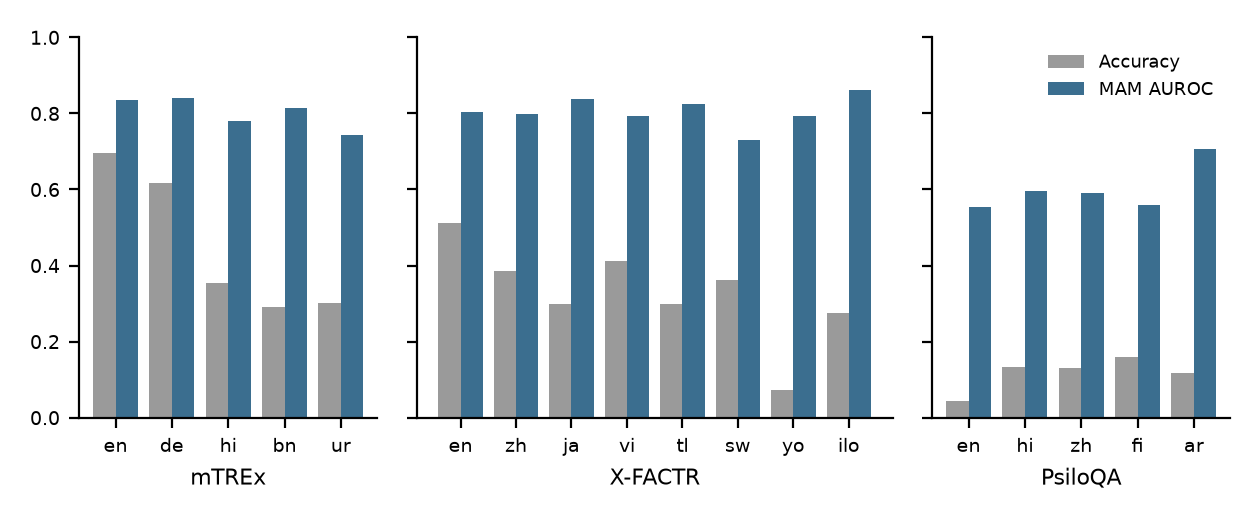

In [7]:
Image(filename=str(RESULTS / 'phase3_acc_auroc.png'), width=720)

## 6. Hand check
A sheet of 50 X-FACTR answers per language was checked by hand against the matcher label. The PRD asks for a second, stem-based label when agreement for a language is under 90%, and for accuracy under both rules. The second label accepts an answer when either `matches()` or `stem_match()` accepts it.

In [8]:
agreement, low = handcheck.score(handcheck.SHEET)
display(pd.DataFrame({'agreement': agreement}).round(3))
print('under 90%:', ', '.join(sorted(low)) or 'none')

,agreement
en,0.88
ilo,0.82
ja,0.90
sw,0.84
tl,0.74
vi,0.70
yo,0.84
zh,0.80


under 90%: en, ilo, sw, tl, vi, yo, zh


In [9]:
items = {r['uid']: r for r in read_jsonl(ROOT / 'data' / 'processed' / 'xfactr.jsonl')}
rows = []
for p in LANGS:
    if p.parent.name != 'xfactr':
        continue
    ans = [a for a in read_jsonl(p / 'answers.jsonl') if a['uid'] in items]
    rows.append([p.name, len(ans),
                 sum(matches(a['answer'], items[a['uid']]['gold']) for a in ans) / len(ans),
                 sum(matches(a['answer'], items[a['uid']]['gold']) or stem_match(a['answer'], items[a['uid']]['gold'], p.name)
                     for a in ans) / len(ans)])
pd.DataFrame(rows, columns=['language', 'n', 'accuracy (matches)', 'accuracy (matches or stem)']).round(3)

,language,n,accuracy (matches),accuracy (matches or stem)
0,en,1796,0.513,0.514
1,ilo,834,0.275,0.275
2,ja,1380,0.298,0.299
3,sw,1136,0.362,0.362
4,tl,1215,0.300,0.300
5,vi,1380,0.413,0.413
6,yo,856,0.074,0.074
7,zh,1380,0.386,0.386


## 7. Flags and errors
Flags are written by `python scripts/run_phase3.py verify`. `errors.jsonl` lists items that failed in a stage.

In [10]:
print((RESULTS / 'flags.txt').read_text(encoding='utf-8') or '(no flags)')
rows = []
for p in LANGS:
    f = p / 'errors.jsonl'
    rows.append([p.parent.name, p.name, len(read_jsonl(f)) if f.exists() else 0])
pd.DataFrame(rows, columns=['dataset', 'language', 'error rows'])

psiloqa/en/mam_preds_seed43.jsonl: fewer than 10 items of one class in the test split (8 correct, 192 hallucinated)
psiloqa/en/mam_preds_seed44.jsonl: fewer than 10 items of one class in the test split (9 correct, 191 hallucinated)



,dataset,language,error rows
0,mtrex,bn,0
1,mtrex,de,0
2,mtrex,en,0
3,mtrex,hi,0
4,mtrex,ur,0
5,psiloqa,ar,0
6,psiloqa,en,0
7,psiloqa,fi,0
8,psiloqa,hi,0
9,psiloqa,zh,0


## 8. Example answers
One correct and one hallucinated English answer per dataset. `p_hallucinated` is the MAM fully connected probability for seed 42, shown when the item is in that seed's test split.

In [11]:
rows = []
for dataset in ['mtrex', 'xfactr', 'psiloqa']:
    folder = RESULTS / dataset / 'en'
    items = {r['uid']: r for r in read_jsonl(ROOT / 'data' / 'processed' / f'{dataset}.jsonl')}
    preds = {r['uid']: r['p_hallucinated'] for r in read_jsonl(folder / 'mam_preds_seed42.jsonl') if r['artifact'] == 'fully_connected'}
    answers = read_jsonl(folder / 'answers.jsonl')
    for label in (0, 1):
        a = next(a for a in answers if a['label'] == label)
        item = items[a['uid']]
        rows.append([dataset, item['prompt'][:200], ' | '.join(item['gold'])[:80], a['answer'][:200], label,
                     round(preds[a['uid']], 3) if a['uid'] in preds else None])
pd.set_option('display.max_colwidth', 200)
pd.DataFrame(rows, columns=['dataset', 'prompt', 'gold', 'answer', 'label', 'p_hallucinated (seed 42)'])

,dataset,prompt,gold,answer,label,p_hallucinated (seed 42)
0,mtrex,Question: What is the capital of Somalia?,mogadishan | mogadiscio | mogadishu,Mogadishu.,0,None
1,mtrex,Question: What is the capital of Qabala?,qəbələ,I'm not aware of a country or region named Qabala.,1,None
2,xfactr,Mr. President is a legal term in ___ .,america | u. s. | u. s. a. | u.s. | u.s.a. | us | us of a | usa | united states,"politics. (However, it can also be used in other contexts, but it is most commonly associated with politics.)",0,None
3,xfactr,American Congress is a legal term in ___ .,america | u. s. | u. s. a. | u.s. | u.s.a. | us | us of a | usa | united states,"politics. (However, the answer could also be law, government, etc.)",1,None
4,psiloqa,What is the name of the organization responsible for operating the 2020–21 Top 14 competition?,,The organization responsible for operating the 2020–21 Top 14 competition is the Ligue Nationale de Rugby (LNR).,0,None
5,psiloqa,What is the population of Union Grove Township according to the 2010 census?,,"The population of Union Grove Township according to the 2010 census was 2,392.",1,None
